# Klasifikasi Kemiskinan Berdasarkan Indikator Sosial Ekonomi Kabupaten/Kota di Indonesia Menggunakan Algoritma Random Forest

**A. PREPROCESSING DATA**

Tujuan: membersihkan dan menyiapkan dataset agar siap digunakan untuk proses training Random Forest.

**1. Import Library**

In [2]:
# Library untuk pengolahan data
import pandas as pd
import numpy as np

# Library untuk visualisasi
import matplotlib.pyplot as plt
import seaborn as sns

# Library untuk machine learning
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

# Library untuk evaluasi model
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Agar warning tidak terlalu mengganggu
import warnings
warnings.filterwarnings('ignore')
print("Semua library berhasil diimport!")

Semua library berhasil diimport!


**2. Load Dataset**

In [3]:
from google.colab import files

uploaded = files.upload()

Saving Klasifikasi Tingkat Kemiskinan di Indonesia (1).csv to Klasifikasi Tingkat Kemiskinan di Indonesia (1).csv


**3. Membaca Dataset**

In [4]:
df = pd.read_csv(
    'Klasifikasi Tingkat Kemiskinan di Indonesia (1).csv',
    sep=';'
)

df.head()

,Provinsi,Kab/Kota,Persentase Penduduk Miskin (P0) Menurut Kabupaten/Kota (Persen),Rata-rata Lama Sekolah Penduduk 15+ (Tahun),Pengeluaran per Kapita Disesuaikan (Ribu Rupiah/Orang/Tahun),Indeks Pembangunan Manusia,Umur Harapan Hidup (Tahun),Persentase rumah tangga yang memiliki akses terhadap sanitasi layak,Persentase rumah tangga yang memiliki akses terhadap air minum layak,Tingkat Pengangguran Terbuka,Tingkat Partisipasi Angkatan Kerja,PDRB atas Dasar Harga Konstan menurut Pengeluaran (Rupiah),Klasifikasi Kemiskinan
0,ACEH,Simeulue,"18,98","9,48",7148.0,"66,41","65,28","71,56","87,45","5,71","71,15",1648096.0,0.0
1,ACEH,Aceh Singkil,"20,36","8,68",8776.0,"69,22","67,43","69,56","78,58","8,36","62,85",1780419.0,1.0
2,ACEH,Aceh Selatan,"13,18","8,88",8180.0,"67,44","64,4","62,55","79,65","6,46","60,85",4345784.0,0.0
3,ACEH,Aceh Tenggara,"13,41","9,67",8030.0,"69,44","68,22","62,71","86,71","6,43","69,62",3487157.0,0.0
4,ACEH,Aceh Timur,"14,45","8,21",8577.0,"67,83","68,74","66,75","83,16","7,13","59,48",8433526.0,0.0


**4. Melihat Ukuran Dataset**

In [5]:
print("Jumlah baris :", df.shape[0])
print("Jumlah kolom:", df.shape[1])

Jumlah baris : 999
Jumlah kolom: 13


In [6]:
jumlah_baris_kosong = df.isna().all(axis=1).sum()

print("Jumlah baris kosong:", jumlah_baris_kosong)

Jumlah baris kosong: 485


In [7]:
df = df.dropna(how='all')

print("Jumlah baris setelah menghapus baris kosong:", df.shape[0])

Jumlah baris setelah menghapus baris kosong: 514


**5. Melihat Informasi Dataset**

Tujuannya agar kita memastikan datanya sudah benar-benar masuk.

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 514 entries, 0 to 513
Data columns (total 13 columns):
 #   Column                                                                Non-Null Count  Dtype  
---  ------                                                                --------------  -----  
 0   Provinsi                                                              514 non-null    object 
 1   Kab/Kota                                                              514 non-null    object 
 2   Persentase Penduduk Miskin (P0) Menurut Kabupaten/Kota (Persen)       514 non-null    object 
 3   Rata-rata Lama Sekolah Penduduk 15+ (Tahun)                           514 non-null    object 
 4   Pengeluaran per Kapita Disesuaikan (Ribu Rupiah/Orang/Tahun)          514 non-null    float64
 5   Indeks Pembangunan Manusia                                            514 non-null    object 
 6   Umur Harapan Hidup (Tahun)                                            514 non-null    object 
 7   Pers

In [9]:
df.head()

,Provinsi,Kab/Kota,Persentase Penduduk Miskin (P0) Menurut Kabupaten/Kota (Persen),Rata-rata Lama Sekolah Penduduk 15+ (Tahun),Pengeluaran per Kapita Disesuaikan (Ribu Rupiah/Orang/Tahun),Indeks Pembangunan Manusia,Umur Harapan Hidup (Tahun),Persentase rumah tangga yang memiliki akses terhadap sanitasi layak,Persentase rumah tangga yang memiliki akses terhadap air minum layak,Tingkat Pengangguran Terbuka,Tingkat Partisipasi Angkatan Kerja,PDRB atas Dasar Harga Konstan menurut Pengeluaran (Rupiah),Klasifikasi Kemiskinan
0,ACEH,Simeulue,"18,98","9,48",7148.0,"66,41","65,28","71,56","87,45","5,71","71,15",1648096.0,0.0
1,ACEH,Aceh Singkil,"20,36","8,68",8776.0,"69,22","67,43","69,56","78,58","8,36","62,85",1780419.0,1.0
2,ACEH,Aceh Selatan,"13,18","8,88",8180.0,"67,44","64,4","62,55","79,65","6,46","60,85",4345784.0,0.0
3,ACEH,Aceh Tenggara,"13,41","9,67",8030.0,"69,44","68,22","62,71","86,71","6,43","69,62",3487157.0,0.0
4,ACEH,Aceh Timur,"14,45","8,21",8577.0,"67,83","68,74","66,75","83,16","7,13","59,48",8433526.0,0.0


In [10]:
df.tail()

,Provinsi,Kab/Kota,Persentase Penduduk Miskin (P0) Menurut Kabupaten/Kota (Persen),Rata-rata Lama Sekolah Penduduk 15+ (Tahun),Pengeluaran per Kapita Disesuaikan (Ribu Rupiah/Orang/Tahun),Indeks Pembangunan Manusia,Umur Harapan Hidup (Tahun),Persentase rumah tangga yang memiliki akses terhadap sanitasi layak,Persentase rumah tangga yang memiliki akses terhadap air minum layak,Tingkat Pengangguran Terbuka,Tingkat Partisipasi Angkatan Kerja,PDRB atas Dasar Harga Konstan menurut Pengeluaran (Rupiah),Klasifikasi Kemiskinan
509,PAPUA,Puncak,"36,26","2,16",5412.0,"43,17","65,86","11,43","85,03","0,94","89,43",831070.0,1.0
510,PAPUA,Dogiyai,"28,81","4,94",5415.0,55,"65,85","12,11","71,24","5,68","78,20",906904.0,1.0
511,PAPUA,Intan Jaya,"41,66","3,09",5328.0,"48,34","65,69","0,36","35,01","1,43","75,75",767101.0,1.0
512,PAPUA,Deiyai,"40,59","3,25",4673.0,"49,96","65,36","0,00","85,23","0,79","85,01",841296.0,1.0
513,PAPUA,Kota Jayapura,"11,39","11,57",14937.0,"80,11","70,52","85,31","97,10","11,67","63,75",22852202.0,0.0


In [11]:
display(df.describe(include='all').T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Provinsi,514,34,JAWA TIMUR,38,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Kab/Kota,514,514,Kota Jayapura,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Persentase Penduduk Miskin (P0) Menurut Kabupaten/Kota (Persen),514,452,"5,93",3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Rata-rata Lama Sekolah Penduduk 15+ (Tahun),514,377,"8,03",4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Pengeluaran per Kapita Disesuaikan (Ribu Rupiah/Orang/Tahun),514.0,NaN,NaN,NaN,10324.787938,2717.144186,3976.0,8574.0,10196.5,11719.0,23888.0
Indeks Pembangunan Manusia,514,452,"70,6",4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Umur Harapan Hidup (Tahun),514,411,"71,6",4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Persentase rumah tangga yang memiliki akses terhadap sanitasi layak,514,487,"81,89",3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Persentase rumah tangga yang memiliki akses terhadap air minum layak,514,465,"100,00",11,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Tingkat Pengangguran Terbuka,514,373,"5,86",5,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**6. Mengubah Data Numerik (Encode)**

Dataset kami menggunakan format koma (,) sedangkan Python membaca angka dengan menggunakan titik (.)

6.1 Kolom Numerik

In [12]:
kolom_numerik = [
    'Persentase Penduduk Miskin (P0) Menurut Kabupaten/Kota (Persen)',
    'Rata-rata Lama Sekolah Penduduk 15+ (Tahun)',
    'Pengeluaran per Kapita Disesuaikan (Ribu Rupiah/Orang/Tahun)',
    'Indeks Pembangunan Manusia',
    'Umur Harapan Hidup (Tahun)',
    'Persentase rumah tangga yang memiliki akses terhadap sanitasi layak',
    'Persentase rumah tangga yang memiliki akses terhadap air minum layak',
    'Tingkat Pengangguran Terbuka',
    'Tingkat Partisipasi Angkatan Kerja',
    'PDRB atas Dasar Harga Konstan menurut Pengeluaran (Rupiah)'
]
for kolom in kolom_numerik:
    df[kolom] = (
        df[kolom]
        .astype(str)
        .str.strip()
        .str.replace(',', '.', regex=False)
    )

    df[kolom] = pd.to_numeric(
        df[kolom],
        errors='coerce'
    )

6.2 Target Numerik

In [13]:
df['Klasifikasi Kemiskinan'] = pd.to_numeric(
    df['Klasifikasi Kemiskinan'],
    errors='coerce'
)

df['Klasifikasi Kemiskinan'] = df['Klasifikasi Kemiskinan'].astype(int)

Cek informasi setelah konversi

In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 514 entries, 0 to 513
Data columns (total 13 columns):
 #   Column                                                                Non-Null Count  Dtype  
---  ------                                                                --------------  -----  
 0   Provinsi                                                              514 non-null    object 
 1   Kab/Kota                                                              514 non-null    object 
 2   Persentase Penduduk Miskin (P0) Menurut Kabupaten/Kota (Persen)       514 non-null    float64
 3   Rata-rata Lama Sekolah Penduduk 15+ (Tahun)                           514 non-null    float64
 4   Pengeluaran per Kapita Disesuaikan (Ribu Rupiah/Orang/Tahun)          514 non-null    float64
 5   Indeks Pembangunan Manusia                                            514 non-null    float64
 6   Umur Harapan Hidup (Tahun)                                            514 non-null    float64
 7   Pers

In [15]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Persentase Penduduk Miskin (P0) Menurut Kabupaten/Kota (Persen),514.0,1.227315e+01,7.458703e+00,2.38,7.150000e+00,10.455,1.488750e+01,4.166000e+01
Rata-rata Lama Sekolah Penduduk 15+ (Tahun),514.0,8.436615e+00,1.630842e+00,1.42,7.510000e+00,8.305,9.337500e+00,1.283000e+01
Pengeluaran per Kapita Disesuaikan (Ribu Rupiah/Orang/Tahun),514.0,1.032479e+04,2.717144e+03,3976.00,8.574000e+03,10196.500,1.171900e+04,2.388800e+04
Indeks Pembangunan Manusia,514.0,6.992677e+01,6.497033e+00,32.84,6.664250e+01,69.610,7.311250e+01,8.718000e+01
Umur Harapan Hidup (Tahun),514.0,6.965681e+01,3.447464e+00,55.43,6.738750e+01,69.975,7.204250e+01,7.773000e+01
Persentase rumah tangga yang memiliki akses terhadap sanitasi layak,514.0,7.720224e+01,1.858355e+01,0.00,7.021750e+01,81.800,8.988250e+01,9.997000e+01
Persentase rumah tangga yang memiliki akses terhadap air minum layak,514.0,8.513661e+01,1.570166e+01,0.00,7.904250e+01,89.795,9.640000e+01,1.000000e+02
Tingkat Pengangguran Terbuka,514.0,5.059494e+00,2.636970e+00,0.00,3.180000e+00,4.565,6.530000e+00,1.337000e+01
Tingkat Partisipasi Angkatan Kerja,514.0,6.946446e+01,6.396405e+00,56.39,6.507000e+01,68.955,7.234250e+01,9.793000e+01
PDRB atas Dasar Harga Konstan menurut Pengeluaran (Rupiah),514.0,2.196408e+07,4.790492e+07,147485.00,3.654292e+06,8814925.500,1.973510e+07,4.600810e+08


**7. Data Cleaning**

**7.1 Cek Missing Value**

In [16]:
missing_df = pd.DataFrame({
    'Kolom': df.columns,
    'Jumlah Missing': df.isnull().sum().values
})

missing_df

,Kolom,Jumlah Missing
0,Provinsi,0
1,Kab/Kota,0
2,Persentase Penduduk Miskin (P0) Menurut Kabupa...,0
3,Rata-rata Lama Sekolah Penduduk 15+ (Tahun),0
4,Pengeluaran per Kapita Disesuaikan (Ribu Rupia...,0
5,Indeks Pembangunan Manusia,0
6,Umur Harapan Hidup (Tahun),0
7,Persentase rumah tangga yang memiliki akses te...,0
8,Persentase rumah tangga yang memiliki akses te...,0
9,Tingkat Pengangguran Terbuka,0


**7.3 Cek Duplikasi**

In [17]:
print("Jumlah data duplikat:", df.duplicated().sum())

Jumlah data duplikat: 0


Melihat Distribusi Target:
Imbalanced classification.


In [18]:
print(df['Klasifikasi Kemiskinan'].value_counts())

Klasifikasi Kemiskinan
0    452
1     62
Name: count, dtype: int64


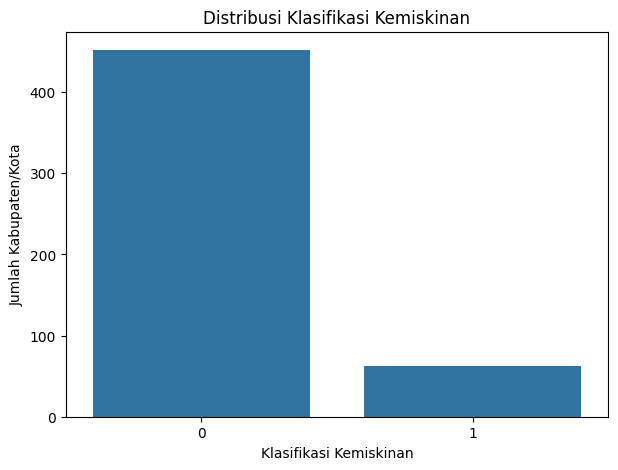

In [19]:
plt.figure(figsize=(7, 5))

sns.countplot(
    x='Klasifikasi Kemiskinan',
    data=df
)

plt.title('Distribusi Klasifikasi Kemiskinan')
plt.xlabel('Klasifikasi Kemiskinan')
plt.ylabel('Jumlah Kabupaten/Kota')

plt.show()

**8. Heatmap Korelasi**

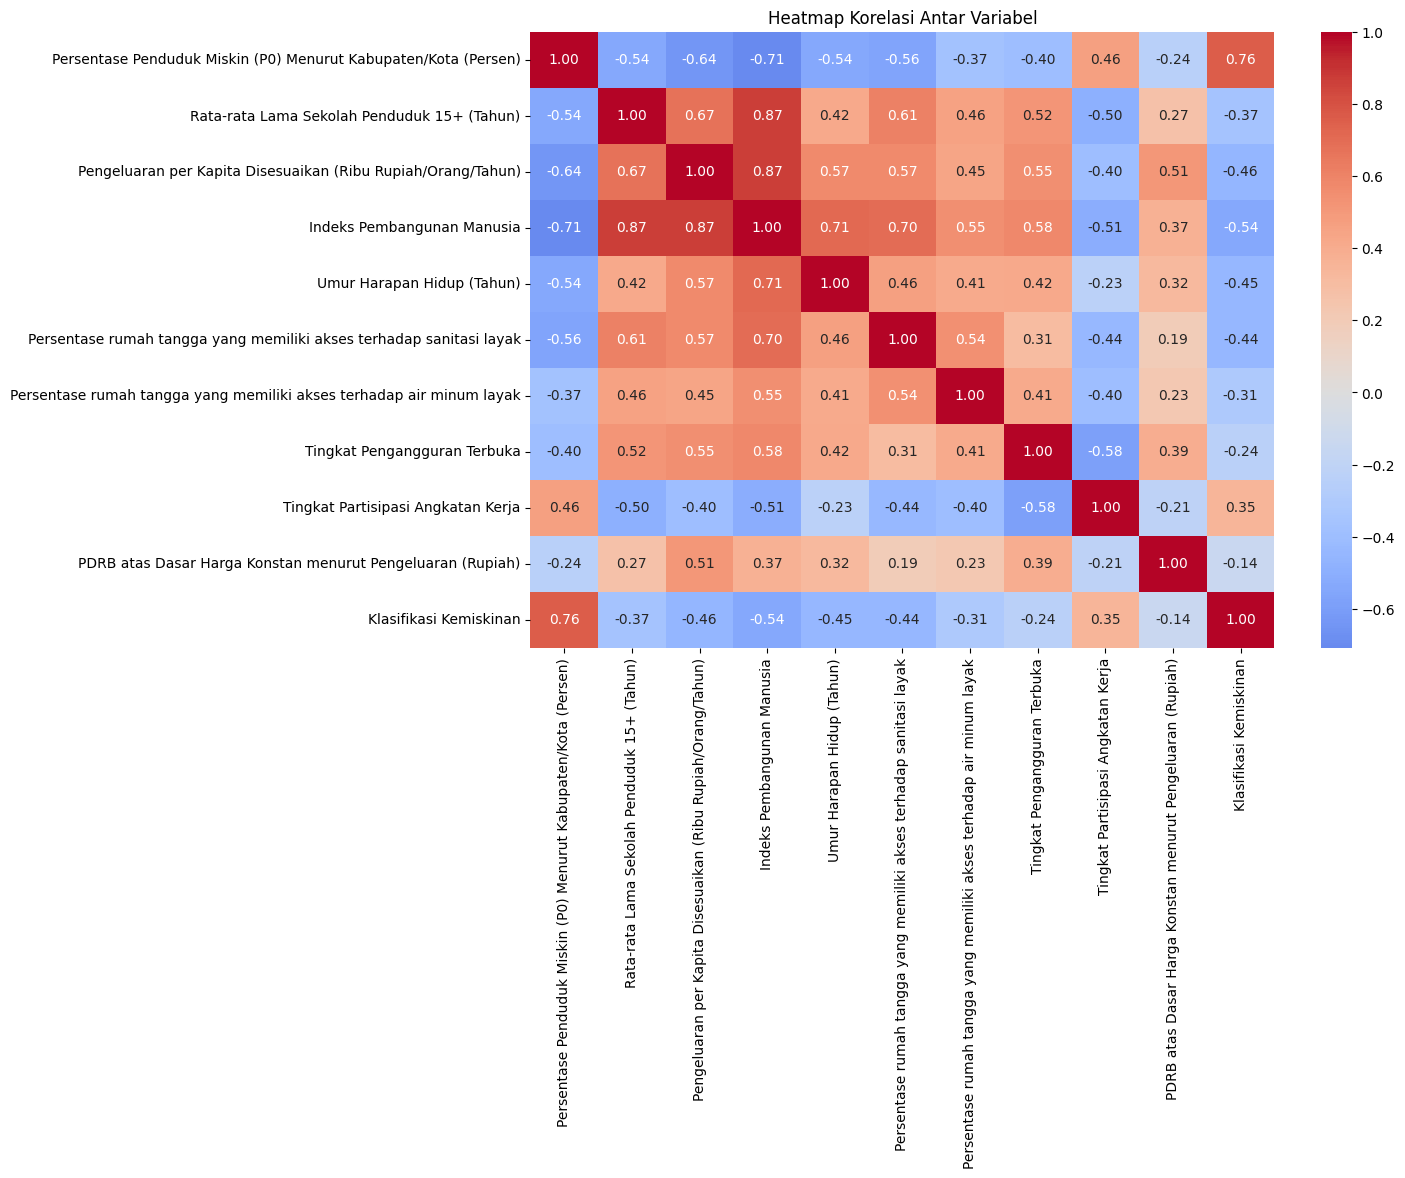

In [20]:
plt.figure(figsize=(12, 8))

corr = df.select_dtypes(include=np.number).corr()

sns.heatmap(
    corr,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0
)

plt.title('Heatmap Korelasi Antar Variabel')
plt.show()

**B. TRAINING/PEMBENTUKAN MODEL**

**9. Penentuan Fitur dan Target**

**1. Menentukan Fitur dan Target**

**Fitur (X)** digunakan sebagai variabel prediktor,
sedangkan Klasifikasi_Kemiskinan digunakan sebagai **target (y)**.


```

Mengeluarkan:

Provinsi (identitas)

→ kategorikal dan bukan indikator sosial ekonomi langsung.

Kab/Kota (identitas)

→ identitas wilayah, bukan indikator numerik. Kalau dimasukkan sembarangan, model bisa belajar nama wilayah daripada karakteristik kemiskinan.

P0

→ berpotensi menjadi leakage karena merupakan ukuran langsung persentase penduduk miskin.

In [21]:
fitur = [
    'Rata-rata Lama Sekolah Penduduk 15+ (Tahun)',
    'Pengeluaran per Kapita Disesuaikan (Ribu Rupiah/Orang/Tahun)',
    'Indeks Pembangunan Manusia',
    'Umur Harapan Hidup (Tahun)',
    'Persentase rumah tangga yang memiliki akses terhadap sanitasi layak',
    'Persentase rumah tangga yang memiliki akses terhadap air minum layak',
    'Tingkat Pengangguran Terbuka',
    'Tingkat Partisipasi Angkatan Kerja',
    'PDRB atas Dasar Harga Konstan menurut Pengeluaran (Rupiah)'
]

nama_singkat = [
    'RLS',
    'Pengeluaran_PerKapita',
    'IPM',
    'UHH',
    'Sanitasi_Layak',
    'Air_Minum_Layak',
    'TPT',
    'TPAK',
    'PDRB'
]

X = df[fitur].copy()
X.columns = nama_singkat

y = df['Klasifikasi Kemiskinan']

**2. Train-Test Split**

Dataset dibagi menjadi data training sebesar 80% dan
data testing sebesar 20% dengan stratifikasi target.

In [22]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Data training :", X_train.shape)
print("Data testing  :", X_test.shape)

print("\nDistribusi target training:")
print(y_train.value_counts().sort_index())

print("\nDistribusi target testing:")
print(y_test.value_counts().sort_index())

Data training : (411, 9)
Data testing  : (103, 9)

Distribusi target training:
Klasifikasi Kemiskinan
0    361
1     50
Name: count, dtype: int64

Distribusi target testing:
Klasifikasi Kemiskinan
0    91
1    12
Name: count, dtype: int64


**3. Random Forest Baseline**

In [23]:
model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight='balanced'
)

model.fit(X_train, y_train)

RandomForestClassifier(class_weight='balanced', n_estimators=200,
                       random_state=42)

**4. Prediksi**

In [24]:
y_pred = model.predict(X_test)
print("Prediksi berhasil dilakukan.")

Prediksi berhasil dilakukan.


**5. Evaluasi**

**5.1 Accuracy, Precision, Recall, F1-Score**

In [25]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(
    y_test,
    y_pred,
    zero_division=0
)
recall = recall_score(
    y_test,
    y_pred,
    zero_division=0
)
f1 = f1_score(
    y_test,
    y_pred,
    zero_division=0
)

print("===== HASIL EVALUASI RANDOM FOREST =====")
print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")

===== HASIL EVALUASI RANDOM FOREST =====
Accuracy  : 0.9417
Precision : 0.7500
Recall    : 0.7500
F1-Score  : 0.7500


**5.2 Classification Report**

In [26]:
print("=== CLASSIFICATION REPORT ===")
print(
    classification_report(
        y_test,
        y_pred,
        zero_division=0
    )
)

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

           0       0.97      0.97      0.97        91
           1       0.75      0.75      0.75        12

    accuracy                           0.94       103
   macro avg       0.86      0.86      0.86       103
weighted avg       0.94      0.94      0.94       103



**5.3 Confusion Matrix**

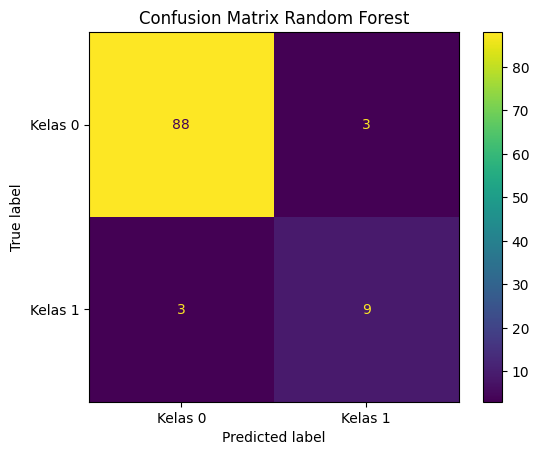

In [27]:
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Kelas 0', 'Kelas 1']
)

disp.plot()

plt.title('Confusion Matrix Random Forest')
plt.show()

**6. Feature Importance**

In [28]:
importance = pd.DataFrame({
    'Fitur': X.columns,
    'Importance': model.feature_importances_
})

importance = importance.sort_values(
    by='Importance',
    ascending=False
)

importance

,Fitur,Importance
1,Pengeluaran_PerKapita,0.240942
2,IPM,0.220194
3,UHH,0.164552
8,PDRB,0.099888
0,RLS,0.073245
4,Sanitasi_Layak,0.064534
6,TPT,0.058284
7,TPAK,0.039368
5,Air_Minum_Layak,0.038993


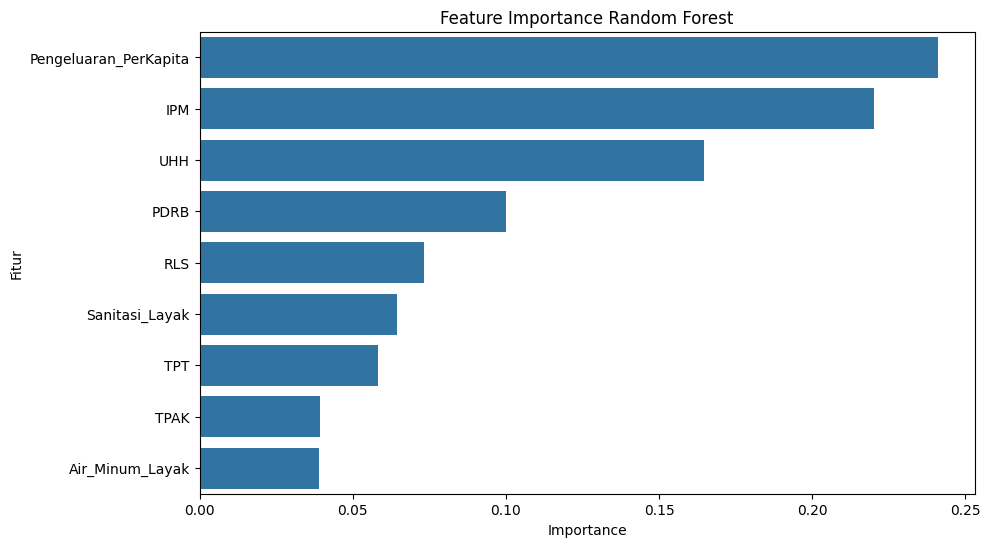

In [29]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance,
    x='Importance',
    y='Fitur'
)

plt.title('Feature Importance Random Forest')
plt.xlabel('Importance')
plt.ylabel('Fitur')

plt.show()

**Inference**

In [30]:
# ============================================================
# INFERENCE RANDOM FOREST
# ============================================================

print("=" * 60)
print("             INFERENCE RANDOM FOREST")
print("=" * 60)

# ------------------------------------------------------------
# 1. MELIHAT RENTANG DATA TRAINING
# ------------------------------------------------------------

print("\nRentang nilai fitur yang digunakan saat training:")
print("-" * 60)

for kolom in X.columns:
    print(
        f"{kolom:25s} : "
        f"{X[kolom].min():,.2f} - {X[kolom].max():,.2f}"
    )

# ------------------------------------------------------------
# 2. INPUT DATA BARU
# ------------------------------------------------------------

print("\n")
print("=" * 60)
print("MASUKKAN DATA BARU")
print("=" * 60)

rls = float(input("1. RLS (tahun)                         : "))
pengeluaran = float(input("2. Pengeluaran_PerKapita (ribu rupiah): "))
ipm = float(input("3. IPM                                : "))
uhh = float(input("4. UHH (tahun)                        : "))
sanitasi = float(input("5. Sanitasi_Layak (%)                : "))
air_minum = float(input("6. Air_Minum_Layak (%)               : "))
tpt = float(input("7. TPT (%)                            : "))
tpak = float(input("8. TPAK (%)                           : "))
pdrb = float(input("9. PDRB                               : "))

# ------------------------------------------------------------
# 3. MEMBUAT DATA BARU
# Nama kolom SAMA dengan X saat training
# ------------------------------------------------------------

data_baru = pd.DataFrame([[
    rls,
    pengeluaran,
    ipm,
    uhh,
    sanitasi,
    air_minum,
    tpt,
    tpak,
    pdrb
]], columns=[
    'RLS',
    'Pengeluaran_PerKapita',
    'IPM',
    'UHH',
    'Sanitasi_Layak',
    'Air_Minum_Layak',
    'TPT',
    'TPAK',
    'PDRB'
])

# ------------------------------------------------------------
# 4. CEK APAKAH INPUT DI LUAR RENTANG DATA TRAINING
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("PEMERIKSAAN INPUT")
print("=" * 60)

ada_di_luar_rentang = False

for kolom in X.columns:

    nilai = data_baru[kolom].iloc[0]
    nilai_min = X[kolom].min()
    nilai_max = X[kolom].max()

    if nilai < nilai_min or nilai > nilai_max:
        print(
            f"⚠️ {kolom}: {nilai:,.2f} "
            f"(di luar rentang {nilai_min:,.2f} - {nilai_max:,.2f})"
        )
        ada_di_luar_rentang = True

if not ada_di_luar_rentang:
    print("✅ Semua nilai berada dalam rentang data training.")

# ------------------------------------------------------------
# 5. PREDIKSI
# ------------------------------------------------------------

prediksi = model.predict(data_baru)[0]

probabilitas = model.predict_proba(data_baru)[0]

# ------------------------------------------------------------
# 6. HASIL
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("HASIL INFERENCE")
print("=" * 60)

display(data_baru)

print(f"\nPrediksi Kelas       : {prediksi}")

if prediksi == 0:
    print("Klasifikasi          : Kelas 0")
else:
    print("Klasifikasi          : Kelas 1")

print(f"Probabilitas Kelas 0 : {probabilitas[0]:.2%}")
print(f"Probabilitas Kelas 1 : {probabilitas[1]:.2%}")

print("=" * 60)

             INFERENCE RANDOM FOREST

Rentang nilai fitur yang digunakan saat training:
------------------------------------------------------------
RLS                       : 1.42 - 12.83
Pengeluaran_PerKapita     : 3,976.00 - 23,888.00
IPM                       : 32.84 - 87.18
UHH                       : 55.43 - 77.73
Sanitasi_Layak            : 0.00 - 99.97
Air_Minum_Layak           : 0.00 - 100.00
TPT                       : 0.00 - 13.37
TPAK                      : 56.39 - 97.93
PDRB                      : 147,485.00 - 460,081,046.00


MASUKKAN DATA BARU
1. RLS (tahun)                         : 8
2. Pengeluaran_PerKapita (ribu rupiah): 10000
3. IPM                                : 70
4. UHH (tahun)                        : 70
5. Sanitasi_Layak (%)                : 80
6. Air_Minum_Layak (%)               : 85
7. TPT (%)                            : 5
8. TPAK (%)                           : 70
9. PDRB                               : 5000000

PEMERIKSAAN INPUT
✅ Semua nilai berada da

,RLS,Pengeluaran_PerKapita,IPM,UHH,Sanitasi_Layak,Air_Minum_Layak,TPT,TPAK,PDRB
0,8.0,10000.0,70.0,70.0,80.0,85.0,5.0,70.0,5000000.0



Prediksi Kelas       : 0
Klasifikasi          : Kelas 0
Probabilitas Kelas 0 : 100.00%
Probabilitas Kelas 1 : 0.00%
